In [2]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# # Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# # Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

# import kagglehub
# # kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

In [ ]:
# train = pd.read_csv("/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")

In [ ]:
# train.shape

(45572, 5)

In [ ]:
# train.head()

,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128


In [ ]:
# train['has'] = train['mask_rle'].notna() & (train['mask_rle'].str.strip() != '')

# pos = train[train['has']]

# print(pos['defect_type'].value_counts())          # per-class positives

# per_image = pos.groupby('image_id')['defect_type'].count()

# print(per_image.value_counts().sort_index())      # cardinality distribution

# clean = train['image_id'].count() - pos['image_id'].count()

# print('clean:', clean)

defect_type
defect_c    4100
defect_d    1707
defect_a    1081
defect_b     313
Name: count, dtype: int64
defect_type
1    4679
2    1072
3     126
Name: count, dtype: int64
clean: 38371


## Milestone 1: full question work (Q1–Q12)

In [1]:
# 1

import numpy as np 
import pandas as pd

df = pd.read_csv("/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv")
df.to_csv("submission.csv", index=False)

In [2]:
# 2

from pathlib import Path

DATA_DIR = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")

# Training annotations
train_path = DATA_DIR / "train.csv"
df = pd.read_csv(train_path)

# Submission template
sample_path = DATA_DIR / "sample_submission.csv"
sample_submission = pd.read_csv(sample_path)
sample_submission.to_csv("submission.csv", index=False)

print("Training annotation shape:", df.shape)
print("Training columns:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nSubmission template shape:", sample_submission.shape)

Training annotation shape: (45572, 5)
Training columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height']

First five rows:


,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128



Submission template shape: (12000, 4)


In [3]:
# 3
print("Rows:", len(df))
print("Unique images:", df["image_id"].nunique())
print("Defect categories:", sorted(df["defect_type"].dropna().unique()))

print("\nImage dimensions:")
display(df[["width", "height"]].drop_duplicates())

print("\nRows per image:")
display(df.groupby("image_id").size().value_counts().sort_index())

print("\nMissing values:")
display(df.isna().sum())

print("\nRows per defect category:")
display(df["defect_type"].value_counts())

Rows: 45572
Unique images: 11393
Defect categories: ['defect_a', 'defect_b', 'defect_c', 'defect_d']

Image dimensions:


,width,height
0,800,128



Rows per image:


4    11393
Name: count, dtype: int64


Missing values:


image_id           0
defect_type        0
mask_rle       38371
width              0
height             0
dtype: int64


Rows per defect category:


defect_type
defect_a    11393
defect_b    11393
defect_c    11393
defect_d    11393
Name: count, dtype: int64

In [4]:
# 4

classes = sorted(df["defect_type"].dropna().unique())

# True if an image-category pair has a non-empty RLE mask
df["has_defect"] = (
    df["mask_rle"].fillna("").astype(str).str.strip().ne("")
)

# One row per image, one column per defect category
presence = (
    df.pivot_table(
        index="image_id",
        columns="defect_type",
        values="has_defect",
        aggfunc="max",
        fill_value=False
    )
    .reindex(columns=classes, fill_value=False)
    .astype(bool)
)

print("Positive images per class:")
display(presence.sum().sort_values(ascending=False).to_frame("positive_images"))

# Clean means no defect category is present
clean_count = (~presence.any(axis=1)).sum()

print("Completely clean images:", int(clean_count))

# Number of defect categories present in each image
labels_per_image = presence.sum(axis=1)

print("Images with exactly one defect category:",
      int((labels_per_image == 1).sum()))

print("Images with multiple defect categories:",
      int((labels_per_image > 1).sum()))

print("Images with no defect categories:",
      int((labels_per_image == 0).sum()))

Positive images per class:


,positive_images
defect_type,
defect_c,4100
defect_d,1707
defect_a,1081
defect_b,313


Completely clean images: 5516
Images with exactly one defect category: 4679
Images with multiple defect categories: 1198
Images with no defect categories: 5516


In [5]:
# 5

import re

H, W = 128, 800
N_PIXELS = H * W

def decode_rle(rle, height=H, width=W):
    """Decode 1-indexed start-length RLE in column-major order."""
    mask = np.zeros(height * width, dtype=np.uint8)

    if pd.isna(rle) or not str(rle).strip():
        return mask.reshape((height, width), order="F")

    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)

    if len(values) % 2:
        raise ValueError(f"Odd number of RLE values: {rle}")

    starts = values[0::2]
    lengths = values[1::2]
    ends = starts + lengths - 1

    if np.any(starts < 1) or np.any(lengths < 0):
        raise ValueError("Invalid RLE start or length.")

    if np.any(ends > height * width):
        raise ValueError("RLE run exceeds the image boundary.")

    for start, end in zip(starts, ends):
        mask[start - 1:end] = 1

    return mask.reshape((height, width), order="F")

In [6]:
# 6

def inspect_rle(rle, height, width):
    if pd.isna(rle) or not str(rle).strip():
        return 0, 0, 0

    values = np.fromstring(str(rle), sep=" ", dtype=np.int64)

    if len(values) % 2:
        return 1, 0, 0

    starts = values[0::2]
    lengths = values[1::2]
    ends = starts + lengths - 1
    limit = height * width

    malformed = (
        np.any(starts < 1)
        or np.any(lengths <= 0)
        or np.any(ends > limit)
    )

    return int(malformed), int(ends.max(initial=0)), int((ends > limit).sum())

checks = df.apply(
    lambda row: inspect_rle(row["mask_rle"], int(row["height"]), int(row["width"])),
    axis=1
)

df[["rle_malformed", "max_run_end", "runs_past_boundary"]] = pd.DataFrame(
    checks.tolist(), index=df.index
)

print("Rows with malformed RLE:", int(df["rle_malformed"].sum()))
print("Maximum run-ending pixel index:", int(df["max_run_end"].max()))
print("Runs beyond image boundaries:", int(df["runs_past_boundary"].sum()))

Rows with malformed RLE: 0
Maximum run-ending pixel index: 102400
Runs beyond image boundaries: 0


In [7]:
# 7
overlap_count = 0
overlap_examples = []

for image_id, group in df.groupby("image_id", sort=False):
    class_masks = []

    for _, row in group.iterrows():
        mask = decode_rle(row["mask_rle"], int(row["height"]), int(row["width"]))
        class_masks.append(mask)

    if len(class_masks) > 1:
        pixel_counts = np.sum(class_masks, axis=0)
        overlap_pixels = int((pixel_counts > 1).sum())

        if overlap_pixels:
            overlap_count += overlap_pixels
            overlap_examples.append((image_id, overlap_pixels))

print("Total pixels assigned to multiple classes:", overlap_count)
print("Images with spatial overlap:", len(overlap_examples))
print("First overlap examples:", overlap_examples[:10])

Total pixels assigned to multiple classes: 0
Images with spatial overlap: 0
First overlap examples: []


In [8]:
# 8
original_h, original_w = 128, 800
target_h, target_w = 256, 256

scale_x = target_w / original_w
scale_y = target_h / original_h
distortion_ratio = scale_y / scale_x

print(f"Horizontal scale: {scale_x:.4f}")
print(f"Vertical scale: {scale_y:.4f}")
print(f"Vertical-to-horizontal scale ratio: {distortion_ratio:.4f}")

Horizontal scale: 0.3200
Vertical scale: 2.0000
Vertical-to-horizontal scale ratio: 6.2500


In [9]:
# 9 Q6: of Milestone 1

# from pathlib import Path

# for p in Path("/kaggle/input").rglob("*"):
#     if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif", ".tiff"}:
#         print(p)
#         break

from pathlib import Path

image_extensions = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

image_paths = [
    p for p in Path("/kaggle/input").rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Number of image files found:", len(image_paths))
for p in image_paths[:15]:
    print(p)

Number of image files found: 14393
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/LZ46LTL6O2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/13H1VTAZ42.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/G0DWU2GK1L.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/CVPHC0DT1P.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/90XJFQDL7G.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/3V8LZ56MOW.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/Y9EUV6TNP2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/K76P42J0GK.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/ZSS7THB1UM.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/8JNHXLSBU3.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/pu

In [10]:
from pathlib import Path

DATA_DIR = Path(
    "/kaggle/input/competitions/industrial-surface-defect-detection/public"
)

train_image_dir = DATA_DIR / "train"
test_image_dir = DATA_DIR / "test"

train_images = list(train_image_dir.glob("*.jpg"))
test_images = list(test_image_dir.glob("*.jpg"))

print("Training images:", len(train_images))
print("Test images:", len(test_images))

print("\nTraining image examples:")
for p in train_images[:5]:
    print(p)

Training images: 11393
Test images: 3000

Training image examples:
/kaggle/input/competitions/industrial-surface-defect-detection/public/train/I2P3TOD3FY.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/train/2GYBBED7DJ.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/train/DFRBLMRLQ9.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/train/I7GTCUX6HT.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/train/OMXK41V3QA.jpg


Image ID: 4S22I7SA34
Defect class: defect_a
Image path: /kaggle/input/competitions/industrial-surface-defect-detection/public/train/4S22I7SA34.jpg
Image exists: True
Image dimensions: (800, 128)


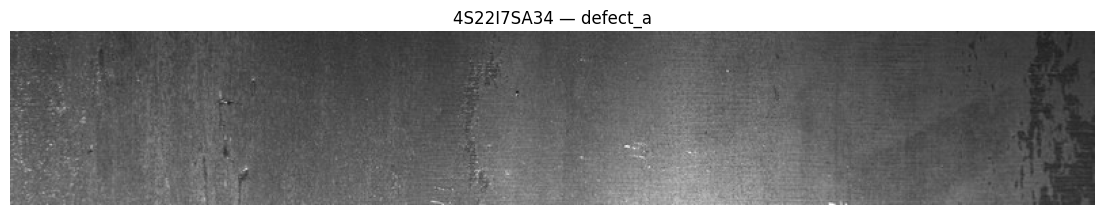

In [11]:
from PIL import Image
import matplotlib.pyplot as plt

# Choose one image that has a non-empty annotation
positive_rows = df[df["mask_rle"].fillna("").astype(str).str.strip().ne("")]

row = positive_rows.iloc[0]
image_path = train_image_dir / f"{row['image_id']}.jpg"

print("Image ID:", row["image_id"])
print("Defect class:", row["defect_type"])
print("Image path:", image_path)
print("Image exists:", image_path.exists())

if image_path.exists():
    image = Image.open(image_path)
    print("Image dimensions:", image.size)

    plt.figure(figsize=(14, 3))
    plt.imshow(image, cmap="gray")
    plt.title(f"{row['image_id']} — {row['defect_type']}")
    plt.axis("off")
    plt.show()

In [12]:

from PIL import Image
# import numpy as np
# import pandas as pd
from scipy import ndimage

def cohens_d(defect_pixels, background_pixels):
    a = np.asarray(defect_pixels, dtype=np.float64)
    b = np.asarray(background_pixels, dtype=np.float64)

    if len(a) < 2 or len(b) < 2:
        return np.nan

    pooled_var = (
        (len(a) - 1) * np.var(a, ddof=1)
        + (len(b) - 1) * np.var(b, ddof=1)
    ) / (len(a) + len(b) - 2)

    if pooled_var <= 0:
        return np.nan

    return (a.mean() - b.mean()) / np.sqrt(pooled_var)


results = []

for class_name in classes:
    class_rows = df[
        (df["defect_type"] == class_name)
        & df["mask_rle"].fillna("").astype(str).str.strip().ne("")
    ]

    image_effect_sizes = []

    for _, row in class_rows.iterrows():
        image_path = train_image_dir / f"{row['image_id']}.jpg"

        if not image_path.exists():
            continue

        image = np.asarray(
            Image.open(image_path).convert("L"),
            dtype=np.float64
        )

        mask = decode_rle(
            row["mask_rle"],
            int(row["height"]),
            int(row["width"])
        ).astype(bool)

        if image.shape != mask.shape or not mask.any():
            continue

        # Define nearby background as pixels within 5 pixels
        # of the defect boundary, excluding defect pixels.
        expanded = ndimage.binary_dilation(
            mask, iterations=5
        )
        background_mask = expanded & ~mask

        if background_mask.sum() < 2:
            continue

        d = cohens_d(
            image[mask],
            image[background_mask]
        )

        if np.isfinite(d):
            image_effect_sizes.append(d)

    results.append({
        "defect_class": class_name,
        "images_analyzed": len(image_effect_sizes),
        "mean_signed_d": (
            np.mean(image_effect_sizes)
            if image_effect_sizes else np.nan
        ),
        "mean_absolute_d": (
            np.mean(np.abs(image_effect_sizes))
            if image_effect_sizes else np.nan
        )
    })

q6_results = pd.DataFrame(results)
display(q6_results)


,defect_class,images_analyzed,mean_signed_d,mean_absolute_d
0,defect_a,1081,-0.037639,0.326568
1,defect_b,313,-0.217251,0.319539
2,defect_c,4100,0.031432,0.412466
3,defect_d,1707,-0.249318,0.456175


In [13]:
# 10 
def cohens_d(defect_pixels, background_pixels):
    a = np.asarray(defect_pixels, dtype=float).ravel()
    b = np.asarray(background_pixels, dtype=float).ravel()

    if len(a) < 2 or len(b) < 2:
        return np.nan

    pooled_var = (
        (len(a) - 1) * np.var(a, ddof=1)
        + (len(b) - 1) * np.var(b, ddof=1)
    ) / (len(a) + len(b) - 2)

    if pooled_var <= 0:
        return np.nan

    return (a.mean() - b.mean()) / np.sqrt(pooled_var)

In [14]:
# 11
def dice_score(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=bool)
    y_pred = np.asarray(y_pred, dtype=bool)

    denominator = y_true.sum() + y_pred.sum()

    if denominator == 0:
        return 1.0

    intersection = np.logical_and(y_true, y_pred).sum()
    return 2 * intersection / denominator

# Q7: Empty ground truth and empty prediction
empty = np.zeros(10, dtype=np.uint8)
print("Empty vs empty:", dice_score(empty, empty))

# Q7: Empty ground truth, two false-positive pixels
prediction = np.zeros(10, dtype=np.uint8)
prediction[[2, 5]] = 1
print("Two false positives vs empty:", dice_score(empty, prediction))

# Q8: Toy metric example, using the weights specified in the form
foreground_dice = 0.6400
false_positive_score = 0.9990
empty_accuracy = 0.9000

weighted_score = (
    0.70 * foreground_dice
    + 0.20 * false_positive_score
    + 0.10 * empty_accuracy
)

print(f"Weighted score: {weighted_score:.4f}")

Empty vs empty: 1.0
Two false positives vs empty: 0.0
Weighted score: 0.7378


In [15]:
# 12

# Each row represents one image-category pair
is_empty = ~df["has_defect"]

naive_mean_dice = is_empty.mean()

# Under the toy official metric from Q8:
# Foreground Dice = 0
# FalsePositiveScore = 1
# EmptyAccuracy = 1
official_all_empty_score = 0.70 * 0 + 0.20 * 1 + 0.10 * 1

print(f"Empty image-class pairs: {int(is_empty.sum())}")
print(f"Total image-class pairs: {len(df)}")
print(f"Naive mean Dice: {naive_mean_dice:.4f}")
print(f"Official all-empty score: {official_all_empty_score:.4f}")

Empty image-class pairs: 38371
Total image-class pairs: 45572
Naive mean Dice: 0.8420
Official all-empty score: 0.3000


In [16]:
# 13
from scipy import ndimage

def component_areas(mask):
    # 8-connected components: pixels can connect diagonally
    structure = np.ones((3, 3), dtype=np.uint8)
    labels, num_components = ndimage.label(mask, structure=structure)

    areas = np.bincount(labels.ravel())[1:]
    return areas

for class_name in classes:
    class_rows = df[df["defect_type"] == class_name]

    all_areas = []
    total_defect_pixels = 0
    removed_pixels = 0

    # Use the threshold specified in the form for each class
    threshold = {"defect_a": 200, "defect_b": 50}.get(class_name, 0)

    for _, row in class_rows.iterrows():
        mask = decode_rle(row["mask_rle"], int(row["height"]), int(row["width"]))
        areas = component_areas(mask)

        all_areas.extend(areas.tolist())
        total_defect_pixels += int(mask.sum())

        if threshold:
            removed_pixels += int(areas[areas < threshold].sum())

    print(f"\n{class_name}")
    print("Smallest component:", min(all_areas) if all_areas else None)
    print("Components found:", len(all_areas))

    if threshold and total_defect_pixels:
        loss_pct = 100 * removed_pixels / total_defect_pixels
        print(f"Pixels removed at threshold {threshold}: {loss_pct:.4f}%")


defect_a
Smallest component: 3
Components found: 2239
Pixels removed at threshold 200: 15.2171%

defect_b
Smallest component: 93
Components found: 341
Pixels removed at threshold 50: 0.0000%

defect_c
Smallest component: 1
Components found: 9129

defect_d
Smallest component: 1
Components found: 2796


In [17]:
# 14

# Each image becomes a tuple of binary category indicators
label_combinations = presence.apply(
    lambda row: tuple(int(v) for v in row),
    axis=1
)

print("Unique label combinations:", label_combinations.nunique())

print("\nMost common combinations:")
display(
    label_combinations.value_counts()
    .head(20)
    .rename("image_count")
    .to_frame()
)

# Simple proportional count for the rare class
defect_b_count = int(presence["defect_b"].sum())
validation_fraction = 0.20

print("Positive defect_b images:", defect_b_count)
print(
    "Approximate validation count:",
    round(defect_b_count * validation_fraction)
)

Unique label combinations: 15

Most common combinations:


,image_count
"(0, 0, 0, 0)",5516
"(0, 0, 1, 0)",3105
"(0, 0, 0, 1)",822
"(1, 0, 0, 0)",601
"(0, 0, 1, 1)",598
"(1, 0, 1, 0)",215
"(0, 1, 0, 0)",151
"(1, 0, 0, 1)",136
"(1, 0, 1, 1)",87
"(0, 1, 1, 0)",67


Positive defect_b images: 313
Approximate validation count: 63


In [18]:

import os
import random
# import numpy as np
# import pandas as pd
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

DATA_DIR = Path(
    "/kaggle/input/competitions/industrial-surface-defect-detection/public"
)
TRAIN_IMAGE_DIR = DATA_DIR / "train"

CLASSES = ["defect_a", "defect_b", "defect_c", "defect_d"]
HEIGHT, WIDTH = 128, 800

# Make sure the expected columns and variables exist.
print("Data shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Image directory exists:", TRAIN_IMAGE_DIR.exists())
print("Decoder available:", callable(decode_rle))


Device: cpu
Data shape: (45572, 9)
Columns: ['image_id', 'defect_type', 'mask_rle', 'width', 'height', 'has_defect', 'rle_malformed', 'max_run_end', 'runs_past_boundary']
Image directory exists: True
Decoder available: True


In [19]:

# Create one row per image, with one RLE annotation per defect class.
rle_lookup = (
    df.pivot(index="image_id", columns="defect_type", values="mask_rle")
      .reindex(columns=CLASSES)
)

image_ids = rle_lookup.index.to_numpy()

presence = (
    rle_lookup.fillna("")
    .astype(str)
    .apply(lambda col: col.str.strip().ne(""))
)

# Ensure the columns are in the intended class order.
presence = presence[CLASSES]

label_combinations = presence.apply(
    lambda row: "".join(row.astype(int).astype(str)), axis=1
)

combo_counts = label_combinations.value_counts()
strata = label_combinations.where(
    label_combinations.map(combo_counts) >= 2,
    "__rare__"
)

# Stratification can fail if a stratum has fewer than two images.
strata_counts = strata.value_counts()
if strata_counts.min() < 2:
    raise ValueError(
        "Some split strata have fewer than 2 images. "
        "We need to merge rare strata further."
    )

train_ids, val_ids = train_test_split(
    image_ids,
    test_size=0.20,
    random_state=SEED,
    stratify=strata.to_numpy()
)

print("Training images:", len(train_ids))
print("Validation images:", len(val_ids))
print("\nPositive images by class:")
display(presence.sum().rename("all").to_frame())
print("\nValidation positives by class:")
display(presence.loc[val_ids].sum().rename("validation").to_frame())


Training images: 9114
Validation images: 2279

Positive images by class:


,all
defect_type,
defect_a,1081
defect_b,313
defect_c,4100
defect_d,1707



Validation positives by class:


,validation
defect_type,
defect_a,216
defect_b,63
defect_c,820
defect_d,342


In [20]:

class DefectDataset(Dataset):
    def __init__(self, image_ids, rle_lookup, image_dir):
        self.image_ids = list(image_ids)
        self.rle_lookup = rle_lookup
        self.image_dir = Path(image_dir)

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image_id = self.image_ids[index]
        image_path = self.image_dir / f"{image_id}.jpg"

        image = np.asarray(
            Image.open(image_path).convert("L"),
            dtype=np.float32
        ) / 255.0

        masks = []
        for class_name in CLASSES:
            rle = self.rle_lookup.loc[image_id, class_name]
            mask = decode_rle(rle, HEIGHT, WIDTH)
            masks.append(mask.astype(np.float32))

        masks = np.stack(masks, axis=0)

        image = torch.from_numpy(image).unsqueeze(0)
        masks = torch.from_numpy(masks)

        return image, masks


train_ds = DefectDataset(train_ids, rle_lookup, TRAIN_IMAGE_DIR)
val_ds = DefectDataset(val_ids, rle_lookup, TRAIN_IMAGE_DIR)

BATCH_SIZE = 4
NUM_WORKERS = 2

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

# Inspect one batch before training.
images, masks = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image range:", images.min().item(), images.max().item())
print("Mask values:", torch.unique(masks))


Image batch shape: torch.Size([4, 1, 128, 800])
Mask batch shape: torch.Size([4, 4, 128, 800])
Image range: 0.0 1.0
Mask values: tensor([0., 1.])


In [21]:

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class SmallUNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=4, base=16):
        super().__init__()

        self.enc1 = ConvBlock(in_channels, base)
        self.enc2 = ConvBlock(base, base * 2)
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.enc4 = ConvBlock(base * 4, base * 8)

        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(base * 8, base * 16)

        self.up4 = nn.ConvTranspose2d(base * 16, base * 8, 2, 2)
        self.dec4 = ConvBlock(base * 16, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, 2)
        self.dec3 = ConvBlock(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, 2)
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.dec1 = ConvBlock(base * 2, base)

        # Raw logits: apply sigmoid only for inference.
        self.head = nn.Conv2d(base, out_channels, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.head(d1)


model = SmallUNet().to(DEVICE)
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

# Confirm output dimensions.
with torch.no_grad():
    test_output = model(images.to(DEVICE))
print("Model output shape:", test_output.shape)


Model parameters: 1,940,868
Model output shape: torch.Size([4, 4, 128, 800])


In [ ]:

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 5

history = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    total_images = 0

    for batch_images, batch_masks in train_loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)
        batch_masks = batch_masks.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch_images)
        loss = criterion(logits, batch_masks)

        loss.backward()
        optimizer.step()

        batch_size = batch_images.size(0)
        total_loss += loss.item() * batch_size
        total_images += batch_size

    epoch_loss = total_loss / total_images
    history.append(epoch_loss)

    print(f"Epoch {epoch + 1}/{EPOCHS} | train BCE loss: {epoch_loss:.6f}")

torch.save(model.state_dict(), "q12_unet_baseline.pth")
print("Saved model to q12_unet_baseline.pth")


Epoch 1/5 | train BCE loss: 0.045497
Epoch 2/5 | train BCE loss: 0.038217


In [ ]:

THRESHOLDS = [0.3, 0.5, 0.7, 0.9]

# Accumulators for each threshold.
stats = {
    t: {
        "positive_dice_sum": 0.0,
        "positive_pairs": 0,
        "empty_pairs": 0,
        "empty_pairs_with_fp": 0,
        "empty_fp_pixel_fraction_sum": 0.0,
        "empty_correct": 0,
        "all_dice_sum": 0.0,
        "all_pairs": 0,
    }
    for t in THRESHOLDS
}

model.eval()

with torch.no_grad():
    for batch_images, batch_masks in val_loader:
        batch_images = batch_images.to(DEVICE, non_blocking=True)

        # Probabilities from sigmoid, shape: (B, 4, 128, 800).
        y_prob = torch.sigmoid(model(batch_images)).cpu().numpy()
        y_true = batch_masks.numpy().astype(bool)

        for threshold in THRESHOLDS:
            y_pred = y_prob >= threshold

            for i in range(y_true.shape[0]):
                for c in range(y_true.shape[1]):
                    true_mask = y_true[i, c]
                    pred_mask = y_pred[i, c]

                    true_count = int(true_mask.sum())
                    pred_count = int(pred_mask.sum())
                    intersection = int((true_mask & pred_mask).sum())

                    if true_count + pred_count == 0:
                        dice = 1.0
                    else:
                        dice = (
                            2.0 * intersection /
                            (true_count + pred_count)
                        )

                    s = stats[threshold]
                    s["all_dice_sum"] += dice
                    s["all_pairs"] += 1

                    if true_count > 0:
                        s["positive_dice_sum"] += dice
                        s["positive_pairs"] += 1
                    else:
                        s["empty_pairs"] += 1

                        fp_fraction = pred_count / true_mask.size
                        s["empty_fp_pixel_fraction_sum"] += fp_fraction

                        if pred_count > 0:
                            s["empty_pairs_with_fp"] += 1
                        else:
                            s["empty_correct"] += 1

rows = []

for threshold in THRESHOLDS:
    s = stats[threshold]

    fg_dice = (
        s["positive_dice_sum"] / s["positive_pairs"]
        if s["positive_pairs"] else np.nan
    )

    mean_fp_fraction = (
        s["empty_fp_pixel_fraction_sum"] / s["empty_pairs"]
        if s["empty_pairs"] else np.nan
    )

    false_positive_score = (
        1.0 - mean_fp_fraction
        if s["empty_pairs"] else np.nan
    )

    empty_accuracy = (
        s["empty_correct"] / s["empty_pairs"]
        if s["empty_pairs"] else np.nan
    )

    naive_mean_dice = s["all_dice_sum"] / s["all_pairs"]

    official_score = (
        0.70 * fg_dice
        + 0.20 * false_positive_score
        + 0.10 * empty_accuracy
    )

    empty_pair_fp_rate = (
        s["empty_pairs_with_fp"] / s["empty_pairs"]
        if s["empty_pairs"] else np.nan
    )

    rows.append({
        "threshold": threshold,
        "foreground_dice": fg_dice,
        "empty_pair_FP_rate": empty_pair_fp_rate,
        "mean_FP_pixel_fraction": mean_fp_fraction,
        "false_positive_score": false_positive_score,
        "empty_accuracy": empty_accuracy,
        "naive_mean_dice": naive_mean_dice,
        "official_score": official_score,
    })

threshold_results = pd.DataFrame(rows)
display(threshold_results.round(4))

print("Validation image-class pairs:", stats[THRESHOLDS[0]]["all_pairs"])
print("Ground-truth positive pairs:", stats[THRESHOLDS[0]]["positive_pairs"])
print("Ground-truth empty pairs:", stats[THRESHOLDS[0]]["empty_pairs"])
print(
    "Empty-pair proportion:",
    round(
        stats[THRESHOLDS[0]]["empty_pairs"] /
        stats[THRESHOLDS[0]]["all_pairs"],
        4
    )
)

best_threshold = threshold_results.loc[
    threshold_results["official_score"].idxmax(), "threshold"
]
print("Best threshold by official score:", best_threshold)


In [ ]:

threshold_results.to_csv("q12_threshold_results.csv", index=False)

print("Saved threshold table to q12_threshold_results.csv")
print("Saved model to q12_unet_baseline.pth")


In [ ]:
# 15

thresholds = [0.3, 0.5, 0.7, 0.9]

def mean_foreground_dice(y_true, y_pred):
    scores = []

    for true_mask, pred_mask in zip(
        y_true.reshape(-1, *y_true.shape[-2:]),
        y_pred.reshape(-1, *y_pred.shape[-2:])
    ):
        # Exclude empty ground-truth masks from foreground-only Dice
        if true_mask.sum() == 0:
            continue

        scores.append(dice_score(true_mask, pred_mask))

    return float(np.mean(scores)) if scores else np.nan

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(np.uint8)

    fg_dice = mean_foreground_dice(y_true, y_pred)

    empty_pairs = (y_true.sum(axis=(-2, -1)) == 0)
    fp_pairs = empty_pairs & (y_pred.sum(axis=(-2, -1)) > 0)

    fp_rate = (
        fp_pairs.sum() / empty_pairs.sum()
        if empty_pairs.sum() else np.nan
    )

    print(
        f"Threshold={threshold:.1f} | "
        f"Foreground Dice={fg_dice:.4f} | "
        f"Empty-pair false-positive rate={fp_rate:.4f}"
    )